**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**09 | Full-Development Grouped Cross-Validation**

![Stage 09 scientific workflow](../../images/09_workflow.svg)

**Objective:** Compare three classical classifiers across five participant-disjoint Development folds and examine fold-level and paired participant-level performance.

**Dataset:** All 29 HARTH v2.0 Development participants, using the time-safe, 30-feature window cohort defined in Notebook 08.

**Notebook Scope:** Train and evaluate models within Development only; compare Random Forest and Logistic Regression on the same held-out participants. S023 and S032 remain excluded from this Notebook. Earlier exploratory inspection of those reserved recordings means this is not evidence of strict blind final Test evaluation.

**01. Imports and Reusable Project Functions**

In [1]:
# ==================== 01. Imports and Project Environment ====================

# ------------ 1. Import Python tools for portable project paths. -------------
import sys
from pathlib import Path

# ------------ 2. Import NumPy and pandas for cohort data tables. -------------
import numpy as np
import pandas as pd

# ----------- 3. Import Matplotlib and notebook display functions. ------------
import matplotlib.pyplot as plt
from IPython.display import display

# ---------- 4. Locate repository root without fixed machine paths. -----------
root = Path.cwd().resolve()
while not (root / "python_modules/core/data_loading.py").is_file():
    if root.parent == root:
        raise RuntimeError("Open this notebook inside human-movement-intelligence.")
    root = root.parent

# ---------- 5. Register shared Python and HARTH study directories. -----------
sys.path.insert(0, str(root / "python_modules"))
sys.path.insert(0, str(root / "wearable_activity_recognition/code/src"))

# ---------- 6. Import original HARTH data and GroupKFold utilities. ----------
from harth_data import HARTH_SUBJECTS, ACTIVITY_NAMES, prepare_harth_feature_cohort
from core.data_splitting import audit_group_class_coverage

# ---------- 7. Import CV evaluation and paired subject comparison. -----------
from core.group_cross_validation import (
    evaluate_group_cross_validation, compare_models_by_subject,
)

# ---------- 8. Confirm the original research components are ready. -----------
print("HARTH full-development CV components: ready")

HARTH full-development CV components: ready


**02. Reconstruct the Complete 29-Person Development Cohort**

Reuse the source cohort and windowing settings from Notebook 08. Filter the eight-class task after constructing time-safe windows; retrieve cached recordings or download missing files as needed.

In [2]:
# ============== 02. Reconstruct Full Development Feature Cohort ==============

# ------------- 1. Fix the two original reserved Test identities. -------------
RESERVED_TEST = {"S023", "S032"}

# ---------- 2. Identify the remaining 29 Development participants. -----------
DEVELOPMENT_SUBJECTS = sorted(set(HARTH_SUBJECTS) - RESERVED_TEST)

# ------------ 3. Define the documented eight-class activity task. ------------
TASK_CLASSES = tuple(range(1, 9))

# ---------- 4. Check cohort size and absence of reserved Test IDs. -----------
assert len(DEVELOPMENT_SUBJECTS) == 29
assert not (set(DEVELOPMENT_SUBJECTS) & RESERVED_TEST)

# --------- 5. Recreate label-pure windows and statistical features. ----------
features, metadata, overview, excluded = prepare_harth_feature_cohort(
    subjects=DEVELOPMENT_SUBJECTS,
    data_dir=root / "data/raw/harth_v2",
    task_classes=TASK_CLASSES,
    window_size=100, step_size=50, sampling_rate=50,
)

# --------- 6. Verify one feature vector per source metadata record. ----------
assert len(features) == len(metadata)

# ---------- 7. Report the observed 29-person feature-matrix shape. -----------
print("Development feature matrix:", features.shape)

# ----------- 8. Report documented exclusions and Test non-access. ------------
print("Excluded out-of-task windows:", int(overview["excluded_windows"].sum()))
print("Reserved Test participants loaded: NO")

Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S006.csv
HARTH subject S006: 408,709 rows, 6 sensors
Input signal: 408,709 samples, 6 channels
Candidate windows: 8,173
Retained windows: 7,441 | Shape: (7441, 6, 100)
Rejected candidates: 732
Input windows: (7441, 6, 100)
Feature matrix: (7441, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S008.csv
HARTH subject S008: 418,989 rows, 6 sensors
Input signal: 418,989 samples, 6 channels
Candidate windows: 8,378
Retained windows: 7,564 | Shape: (7564, 6, 100)
Rejected candidates: 814
Input windows: (7564, 6, 100)
Feature matrix: (7564, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S009.csv
HARTH subject S009: 154,464 rows, 6 sensors
Input signal: 154,464 samples, 6 channels
Candidate windows: 3,088
Retained windows: 2,885 | Shape: (2885, 6, 1

D:\human-movement-intelligence\studies\wearable_activity_recognition\src\harth_data.py:203: UserWarning: Unexpected HARTH activity codes: [10, 11, 17] (4,512 rows in S030.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S030: 245,994 rows, 6 sensors
Input signal: 245,994 samples, 6 channels
Candidate windows: 4,918
Retained windows: 3,335 | Shape: (3335, 6, 100)
Rejected candidates: 1,583
Input windows: (3335, 6, 100)
Feature matrix: (3335, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S031.csv


D:\human-movement-intelligence\studies\wearable_activity_recognition\src\harth_data.py:203: UserWarning: Unexpected HARTH activity codes: [10, 11] (334 rows in S031.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S031: 269,560 rows, 6 sensors
Input signal: 269,560 samples, 6 channels
Candidate windows: 5,390
Retained windows: 4,411 | Shape: (4411, 6, 100)
Rejected candidates: 979
Input windows: (4411, 6, 100)
Feature matrix: (4411, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S033.csv
HARTH subject S033: 201,688 rows, 6 sensors
Input signal: 201,688 samples, 6 channels
Candidate windows: 4,032
Retained windows: 3,687 | Shape: (3687, 6, 100)
Rejected candidates: 345
Input windows: (3687, 6, 100)
Feature matrix: (3687, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Input windows: (3351, 6, 100)
Feature matrix: (3351, 3

D:\human-movement-intelligence\studies\wearable_activity_recognition\src\harth_data.py:203: UserWarning: Unexpected HARTH activity codes: [10] (1,422 rows in S037.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S037: 206,379 rows, 6 sensors
Input signal: 206,379 samples, 6 channels
Candidate windows: 4,126
Retained windows: 3,468 | Shape: (3468, 6, 100)
Rejected candidates: 658
Input windows: (3468, 6, 100)
Feature matrix: (3468, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S038.csv
HARTH subject S038: 184,992 rows, 6 sensors
Input signal: 184,992 samples, 6 channels
Candidate windows: 3,698
Retained windows: 3,355 | Shape: (3355, 6, 100)
Rejected candidates: 343
Input windows: (3355, 6, 100)
Feature matrix: (3355, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Eligible dataset: 29 subjects, 132,397 windows, 30 features
Development feature matrix: (132397, 30)
Excluded out-of-task windows: 11708
Reserved Test participants loaded: NO


**03. Verify Subject-Disjoint Folds and Class Coverage**

Check that Train and Validation have no participant overlap and that the predefined classes are represented in each fold. The saved fold audit reports complete class coverage, but this alone does not establish model performance.

In [3]:
# =============== 03. Audit All Five Participant-Disjoint Folds ===============

# ------- 1. Inspect class coverage and subject-group fold feasibility. -------
coverage, fold_audit = audit_group_class_coverage(
    labels=metadata["label"].to_numpy(),
    group_ids=metadata["subject_id"].to_numpy(),
    classes=TASK_CLASSES, n_splits=5,
)

# ----------- 2. Display fold membership and source-window counts. ------------
display(fold_audit[[
    "fold", "train_subjects", "validation_subjects",
    "train_windows", "validation_windows",
    "missing_train_classes", "missing_validation_classes",
]])

# ---------- 3. Require all eight task classes in every Train fold. -----------
assert not fold_audit["missing_train_classes"].map(bool).any()

# -------- 4. Require all eight task classes in every Validation fold. --------
assert not fold_audit["missing_validation_classes"].map(bool).any()

# --------------- 5. Confirm the source-data fold audit passed. ---------------
print("Fold class-coverage audit: PASSED")

Group audit: 29 subjects, 132,397 windows, 8 declared classes, 5 folds
Folds missing training classes: 0


,fold,train_subjects,validation_subjects,train_windows,validation_windows,missing_train_classes,missing_validation_classes
0,1,"S006, S008, S009, S012, S013, S014, S016, S017...","S010, S015, S022, S026, S037, S038",106134,26263,(),()
1,2,"S006, S009, S010, S012, S013, S014, S015, S017...","S008, S016, S025, S028, S033, S036",105037,27360,(),()
2,3,"S006, S008, S010, S013, S015, S016, S017, S018...","S009, S012, S014, S019, S027, S030",106915,25482,(),()
3,4,"S008, S009, S010, S012, S014, S015, S016, S017...","S006, S013, S018, S029, S031, S034",104400,27997,(),()
4,5,"S006, S008, S009, S010, S012, S013, S014, S015...","S017, S020, S021, S024, S035",107102,25295,(),()


Fold class-coverage audit: PASSED


**04. Compare Three Models Across Five Development Folds**

Refit each classifier within every fold. Logistic Regression scaling uses that fold's Train observations only. Reserved Test recordings are not loaded.

In [4]:
# =============== 04. Evaluate Classical Models with GroupKFold ===============

# ------- 1. Fit three classical models across five Development folds. --------
fold_results, subject_results, summary = evaluate_group_cross_validation(
    features=features.to_numpy(),
    labels=metadata["label"].to_numpy(),
    group_ids=metadata["subject_id"].to_numpy(),
    classes=TASK_CLASSES,
    n_splits=5, random_state=42,
)

# ----------- 2. Display saved cross-fold model summary statistics. -----------
display(summary.round(4))

# ---------- 3. Inspect original held-out subject and fold metrics. -----------
display(fold_results[[
    "fold", "model", "validation_subjects",
    "validation_windows", "validation_classes_present",
    "macro_f1", "balanced_accuracy",
]].round(4))

Fold 1: Train=23 subjects, Validation=6 subjects
Dummy (most frequent): Validation Macro F1 = 0.0616
Logistic Regression: Validation Macro F1 = 0.8481
Random Forest: Validation Macro F1 = 0.8275
Fold 2: Train=23 subjects, Validation=6 subjects
Dummy (most frequent): Validation Macro F1 = 0.0810
Logistic Regression: Validation Macro F1 = 0.7894
Random Forest: Validation Macro F1 = 0.8685
Fold 3: Train=23 subjects, Validation=6 subjects
Dummy (most frequent): Validation Macro F1 = 0.0927
Logistic Regression: Validation Macro F1 = 0.7541
Random Forest: Validation Macro F1 = 0.8861
Fold 4: Train=23 subjects, Validation=6 subjects
Dummy (most frequent): Validation Macro F1 = 0.0857
Logistic Regression: Validation Macro F1 = 0.6927
Random Forest: Validation Macro F1 = 0.8113
Fold 5: Train=24 subjects, Validation=5 subjects
Dummy (most frequent): Validation Macro F1 = 0.0862
Logistic Regression: Validation Macro F1 = 0.7706
Random Forest: Validation Macro F1 = 0.7760


,model,fold_macro_f1_mean,fold_macro_f1_sd,fold_macro_f1_min,fold_macro_f1_max,subject_macro_f1_fixed_mean,subject_macro_f1_observed_mean
0,Random Forest,0.8339,0.0442,0.7760,0.8861,0.7308,0.8182
1,Logistic Regression,0.7710,0.0563,0.6927,0.8481,0.6945,0.7715
2,Dummy (most frequent),0.0815,0.0118,0.0616,0.0927,0.0616,0.0677


,fold,model,validation_subjects,validation_windows,validation_classes_present,macro_f1,balanced_accuracy
0,1,Logistic Regression,"S010, S015, S022, S026, S037, S038",26263,8,0.8481,0.9151
1,1,Random Forest,"S010, S015, S022, S026, S037, S038",26263,8,0.8275,0.8143
2,1,Dummy (most frequent),"S010, S015, S022, S026, S037, S038",26263,8,0.0616,0.1250
3,2,Random Forest,"S008, S016, S025, S028, S033, S036",27360,8,0.8685,0.8840
4,2,Logistic Regression,"S008, S016, S025, S028, S033, S036",27360,8,0.7894,0.9020
5,2,Dummy (most frequent),"S008, S016, S025, S028, S033, S036",27360,8,0.0810,0.1250
6,3,Random Forest,"S009, S012, S014, S019, S027, S030",25482,8,0.8861,0.8629
7,3,Logistic Regression,"S009, S012, S014, S019, S027, S030",25482,8,0.7541,0.9011
8,3,Dummy (most frequent),"S009, S012, S014, S019, S027, S030",25482,8,0.0927,0.1250
9,4,Random Forest,"S006, S013, S018, S029, S031, S034",27997,8,0.8113,0.8384


**05. Visualise Variation in Held-Out Macro F1**

Compare fold-level Macro F1 across models, accounting for differences in participant composition and window counts. These folds share the Development cohort and do not represent independent replications.

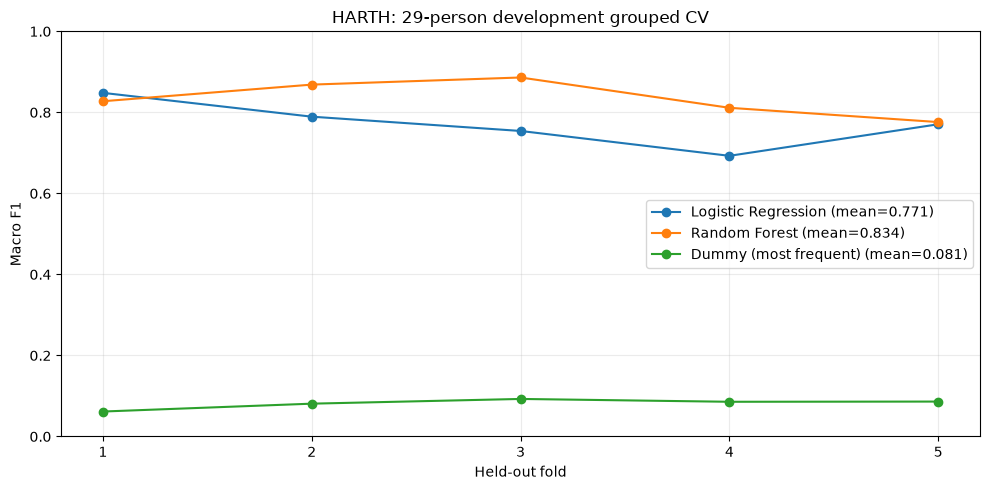

In [5]:
# ================= 05. Visualise Five-Fold Model Performance =================

# ---------- 1. Initialise the original fold-level comparison plot. -----------
fig, ax = plt.subplots(figsize=(10, 5))

# ---------- 2. Plot Macro F1 by held-out fold for each classifier. -----------
for model_name, table in fold_results.groupby("model", sort=False):
    table = table.sort_values("fold")
    ax.plot(table["fold"], table["macro_f1"], marker="o",
            label=f"{model_name} (mean={table['macro_f1'].mean():.3f})")

ax.set(title="HARTH: 29-person development grouped CV",
       xlabel="Held-out fold", ylabel="Macro F1",
       ylim=(0, 1), xticks=[1, 2, 3, 4, 5])
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

**06. Compare Random Forest and Logistic Regression by Person**

Pair fixed eight-class Macro F1 scores for the same 29 held-out Development participants. The metric `difference_a_minus_b` is Random Forest minus Logistic Regression; positive values favour Random Forest.

,subject_id,score_a,score_b,difference_a_minus_b
0,S006,0.7214,0.6136,0.1078
1,S008,0.5236,0.5101,0.0136
2,S009,0.4386,0.3337,0.1049
3,S010,0.4515,0.5134,-0.0620
4,S012,0.9093,0.8800,0.0293
5,S013,0.8546,0.9142,-0.0596
6,S014,0.8621,0.7013,0.1608
7,S015,0.7767,0.8057,-0.0290
8,S016,0.9315,0.8803,0.0512
9,S017,0.7170,0.7640,-0.0470


,model_a,model_b,metric,participants,mean_difference,median_difference,model_a_wins,model_b_wins,ties
0,Random Forest,Logistic Regression,macro_f1_fixed_task,29,0.036297,0.029273,20,9,0


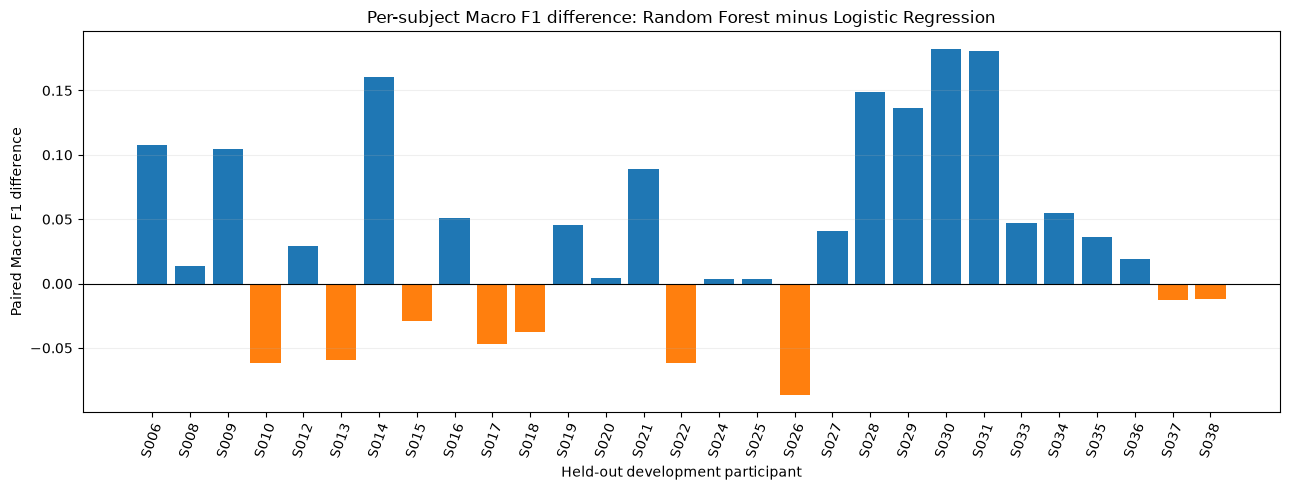

In [6]:
# ============== 06. Pair Random Forest and Logistic Regression ===============

# -------- 1. Pair two model scores for identical Development people. ---------
paired, paired_summary = compare_models_by_subject(
    subject_results,
    model_a="Random Forest",
    model_b="Logistic Regression",
    score_column="macro_f1_fixed_task",
)

# --------- 2. Display signed subject-wise fixed-task Macro F1 gaps. ----------
display(paired.round(4))

# ------------ 3. Display the original paired participant summary. ------------
display(pd.DataFrame([paired_summary]))

# ------------ 4. Initialise the original signed-difference chart. ------------
fig, ax = plt.subplots(figsize=(13, 5))

# --------- 5. Encode positive and negative differences consistently. ---------
bar_colours = ["tab:blue" if value >= 0 else "tab:orange"
               for value in paired["difference_a_minus_b"]]

# ---------- 6. Plot paired Random Forest minus Logistic Regression. ----------
ax.bar(paired["subject_id"], paired["difference_a_minus_b"], color=bar_colours)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Per-subject Macro F1 difference: Random Forest minus Logistic Regression",
       xlabel="Held-out development participant", ylabel="Paired Macro F1 difference")
ax.tick_params(axis="x", rotation=70)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

**07. Compare Activity Support and Individual Model Scores**

Report class availability and fixed-task Macro F1 for each participant. Interpret individual differences alongside activity support rather than relying only on aggregate scores.

In [7]:
# =============== 07. Compare Source Class Support and Results ================

# -------- 1. Count eligible windows and observed classes per person. ---------
person_support = pd.DataFrame({
    "subject_id": coverage.index,
    "eligible_windows": coverage.sum(axis=1).to_numpy(),
    "observed_classes": (coverage > 0).sum(axis=1).to_numpy(),
})

# ------------ 2. Align fixed-eight-class Macro F1 across models. -------------
comparison = subject_results.pivot(
    index="subject_id", columns="model", values="macro_f1_fixed_task"
).reset_index()

# ---------- 3. Join source coverage and model scores by subject ID. ----------
participant_table = person_support.merge(comparison, on="subject_id", how="left")

# --------- 4. Display the original participant-level evidence table. ---------
display(participant_table.round(4))

# --------- 5. Verify all 29 Development individuals are represented. ---------
print("Independent development subjects represented:", len(participant_table))

,subject_id,eligible_windows,observed_classes,Dummy (most frequent),Logistic Regression,Random Forest
0,S006,6708,7,0.1072,0.6136,0.7214
1,S008,7392,6,0.1103,0.5101,0.5236
2,S009,201,4,0.0000,0.3337,0.4386
3,S010,6077,6,0.0331,0.5134,0.4515
4,S012,7309,8,0.1149,0.8800,0.9093
5,S013,6402,8,0.1025,0.9142,0.8546
6,S014,6299,8,0.1070,0.7013,0.8621
7,S015,7453,8,0.0857,0.8057,0.7767
8,S016,6272,8,0.0941,0.8803,0.9315
9,S017,6678,8,0.0985,0.7640,0.7170


Independent development subjects represented: 29


**08. Scientific Quality Gate and Evidence Boundaries**

Verify the five-fold results, participant separation, source integrity and reserved Test exclusion. Because some properties of S023 and S032 were inspected in earlier exploratory work, do not describe the broader research as strictly preregistered and blind.

In [8]:
# ============ 08. Development GroupKFold Scientific Quality Gate =============

# ------------- 1. Check all Development subject IDs are unique. --------------
assert len(DEVELOPMENT_SUBJECTS) == len(set(DEVELOPMENT_SUBJECTS)) == 29

# ------------- 2. Exclude historically reserved Test identities. -------------
assert not (set(DEVELOPMENT_SUBJECTS) & RESERVED_TEST)

# ----------- 3. Confirm results cover all 29 Development subjects. -----------
assert len(subject_results["subject_id"].unique()) == 29

# --------- 4. Ensure original Test people have no evaluated scores. ----------
assert not (set(subject_results["subject_id"]) & RESERVED_TEST)

# --------- 5. Require results for five folds and three classifiers. ----------
assert len(fold_results) == 5 * 3

# ----------- 6. Verify the paired model comparison uses 29 people. -----------
assert len(paired) == 29

# ------------ 7. Check unique person-by-model evaluation records. ------------
assert subject_results.groupby(["model", "subject_id"]).size().eq(1).all()

# ------ 8. Confirm all source-derived statistical features are finite. -------
assert np.isfinite(features.to_numpy()).all()

# ------------- 9. Report passing Development CV quality checks. --------------
print("Full-development GroupKFold: PASSED")

# ------------ 10. State that no reserved Test data were accessed. ------------
print("Original final Test loaded or scored: NO")

# ----------- 11. Maintain the original limits on benchmark claims. -----------
print("Final independent benchmark claim: NOT SUPPORTED")

Full-development GroupKFold: PASSED
Original final Test loaded or scored: NO
Final independent benchmark claim: NOT SUPPORTED
